In [ ]:
from typing import Final
import numpy as np
import statistics
from functools import partial
import marimo as mo
from numpy.typing import NDArray
from pyochain import Iter, Some, NONE, Seq
from collections.abc import Iterable

# Exercise `1.1`.

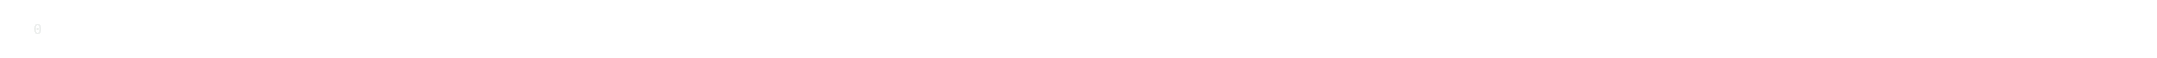

In [ ]:
SEED: int = 0
INSPECTION_PROB: float = 0.05
"""Inspection probability per day."""

RNG = np.random.default_rng(SEED)

def _single_inspection(draw: float) -> int:
    inspected = may_inspect(draw)
    branched = 1 if inspected else 0
    assert branched == int(inspected)
    return branched

def may_inspect(draw: float, prob: float = INSPECTION_PROB) -> bool:
    return draw < prob

_single_inspection(RNG.uniform())

# Exercise `1.2`

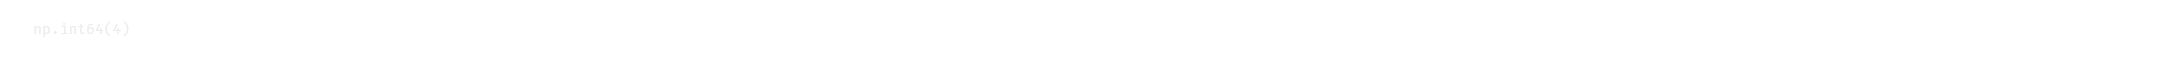

In [ ]:
DAYS_NB: int = 70

# NOTE: I'm still not sure if the for loop was for the sum calculation in itself, the array creation, or both?
def manual_sum(draws: Iterable[float]) -> int:
    count = 0
    for d in draws:
        count += may_inspect(d)
    return count

# This is strictly equivalent to the manual sum and avoid the intermediate array, in case the for loop was only for the elements creation
_ = sum((may_inspect(RNG.uniform()) for _ in range(DAYS_NB)))

manual_sum(np.array([RNG.uniform() for _ in range(DAYS_NB)]))

# Exercise `1.3`

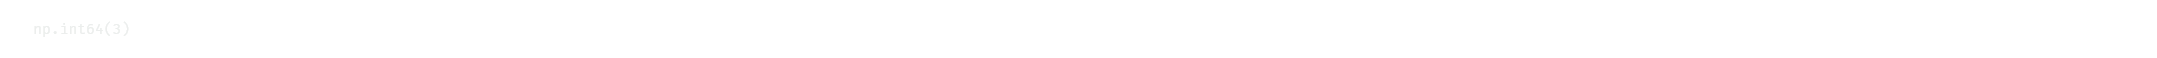

In [ ]:
def _pure_np() -> int:
    arr = RNG.uniform(size=DAYS_NB)
    pure_np = arr.__lt__(INSPECTION_PROB).sum()
    assert manual_sum(arr) == pure_np
    return pure_np

_pure_np()

# Exercises `1.4` + `1.5`

In [ ]:
WORKING_DAYS_PER_MONTH: int = 21
FINE_AMOUNT: int = 100

# Named like that instead of `daysUntilChecked` to avoid issues with my linter (Ruff)7
def days_until_checked(prob: float = INSPECTION_PROB) -> int:
    d = 1
    while True:
        if may_inspect(RNG.uniform(), prob):
            return d
        else:
            d += 1

def _single_cycle_rate(days: int) -> float:
    return FINE_AMOUNT * WORKING_DAYS_PER_MONTH / days

d = days_until_checked()
print(f"Days until checked: {d}")
print(f"Single cycle rate: {_single_cycle_rate(d)}")

Days until checked: 59
Single cycle rate: 35.59322033898305


# Exercise `1.6`

## NOTE:

I struggled a lot to understand some of the instructions phrases exact meaning trough the exercises.

Notably `Call the function m = 10**4 times in a for loop`.

I tought we were referencing a function named `m` at first, not the precedent function.

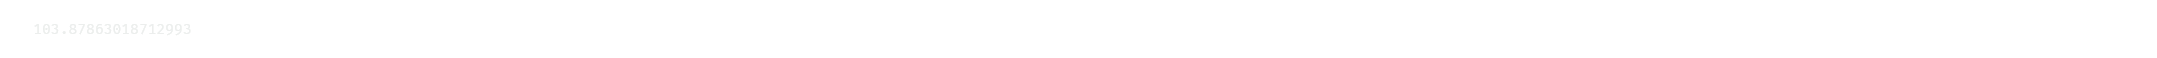

In [ ]:
NB_CALLS: int = 10**4

def _alternatives():
    """Not sure which way was wanted. Using my lib as another alternative example."""

    # `sum` can be swapped by an adapted version of the `manual_sum` function defined above
    _d1 = sum((days_until_checked() for _ in range(NB_CALLS))) / NB_CALLS

    # How I would do it normally.
    _d2 = (
        # Infinite iterator
        Iter.from_fn(lambda: Some(days_until_checked()))
        # Take the first `nb_calls` elements
        .take(NB_CALLS)
        # pass the result to `statistics.mean` to compute the mean
        .pipe(statistics.mean)
    )

def long_run_monthly_fine(prob: float, nb_calls: int) -> float:
    return (
        FINE_AMOUNT
        * WORKING_DAYS_PER_MONTH
        / means_of_days_until_checked(prob, nb_calls)
    )

def means_of_days_until_checked(prob: float, nb_calls: int) -> float:
    # NOTE: As asked, we store the values, but replacing `[...]` by `(...)` is preferable to avoid an unneded intermediate list.
    values = [days_until_checked(prob) for _ in range(nb_calls)]
    return statistics.mean(values)

long_run_monthly_fine(INSPECTION_PROB, NB_CALLS)

# Exercise `1.7`

In [ ]:
def long_run_with_monthly_pass_cost(pass_cost: int = 45) -> None:
    start = INSPECTION_PROB
    p0: float | None = None
    t_limit = _theoretical_limit(pass_cost)
    while True:
        val = 2100 / means_of_days_until_checked(start, NB_CALLS)
        if val < pass_cost:
            p0 = start
            break
        start -= 0.002
    match p0:
        case None:
            print("No probability found")
        case search_result:
            print(f"Search result: {search_result}")
            print(f"Strict inequality at p0: {search_result < t_limit}")
            print(
                f"Expected nb of inspections in {DAYS_NB} days: {search_result * DAYS_NB}"
            )

def _theoretical_limit(pass_cost: int) -> float:
    return pass_cost / (FINE_AMOUNT * WORKING_DAYS_PER_MONTH)

long_run_with_monthly_pass_cost()

Search result: 0.019999999999999976
Strict inequality at p0: True
Expected nb of inspections in 70 days: 1.3999999999999984


# Exercise `2.1`

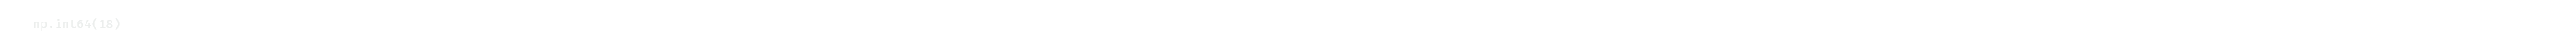

In [ ]:
_DICE_FN = partial(np.random.default_rng(SEED).integers, 1, 7)

def dice(size: int | tuple[int, ...] | None = None) -> NDArray[np.int_]:
    match size:
        case None:
            return _DICE_FN(5)
        case _:
            return _DICE_FN(size=size)

dice().sum()

# Exercise `2.2`

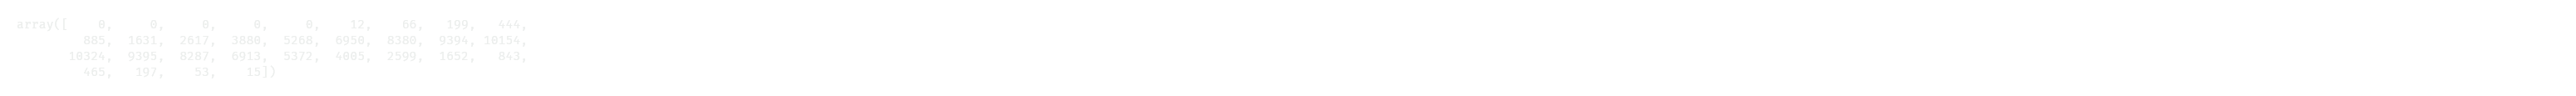

In [ ]:
S = dice((5, 100_000)).sum(axis=0)

score_counts = np.bincount(S)
score_counts

# Exercise `2.3`


A single dice roll has an expected value of 3.5, so the expected value of the sum of 5 dice rolls is 17.5.

This is close with the empirical mode we found: re-running the cell will either give 17 or 18.

In [ ]:
most_frequents = np.asarray(score_counts == score_counts.max()).nonzero()[
    0
]
match len(most_frequents):
    case 0:
        raise ValueError("No max value found")
    case 1:
        print(f"Most frequent value: {most_frequents[0]}")
    case _:
        print(f"Most frequent values (ties): {most_frequents}")

Most frequent value: 18


# Note:

On marimo it's enough to simply "use" the graph objects at the end of the cell to display them.

I use plotly usually so I'm not used to best practices with matplotlib.

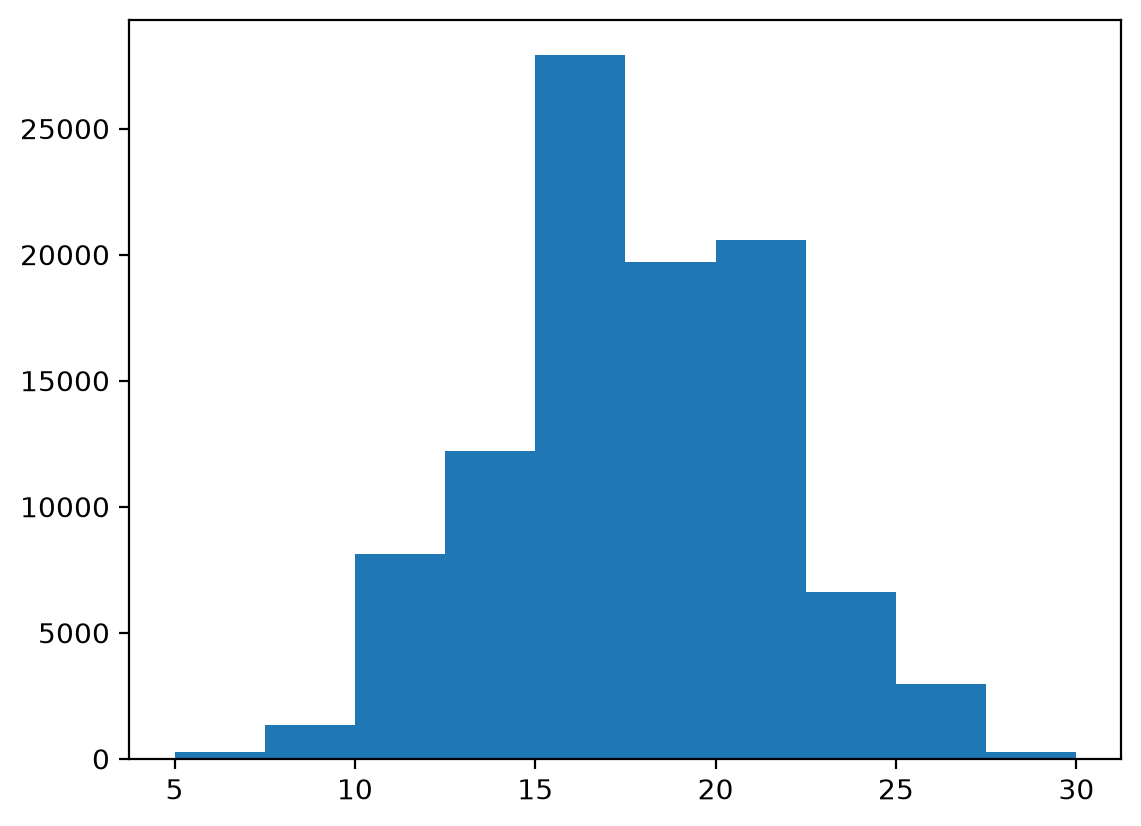

In [ ]:
import matplotlib.pyplot as plt

plt.hist(S)[2]

# Exercice `2.4`

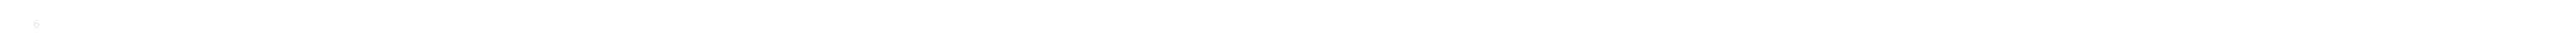

In [ ]:
def nb_throws_to_reach_target_for(target: int) -> int:
    total_points = 0
    for nb_throws in range(1, 21):
        total_points += dice(1)
        if total_points >= target:
            break
    return nb_throws

nb_throws_to_reach_target_for(20)

# Exercice `2.5`.

The iteration limit is not needed since the nb of iterations will be contained between 4 (6 + 6 + 6 + [...]) and 20 (20 * 1).

This hold up as long as `target == limit`.

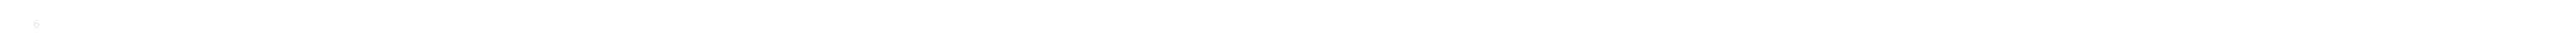

In [ ]:
def _nb_throws_to_reach_target_while(target: int) -> int:
    nb_throws = 0
    total_points = 0
    while True:
        nb_throws += 1
        total_points += dice(1)
        if total_points >= target:
            break
    return nb_throws

_nb_throws_to_reach_target_while(20)

# Exercice `2.6`

In [ ]:
def scoremin(m: int) -> int:
    match m:
        case _ if m < 1:
            raise ValueError("m must be positive")
        case 1:
            # A throw is always at least 1, better to short-circuit
            return 1
        case _:
            # the range version avoid the counter handling in bytecode
            return nb_throws_to_reach_target_for(m)

# Exercice `2.7`

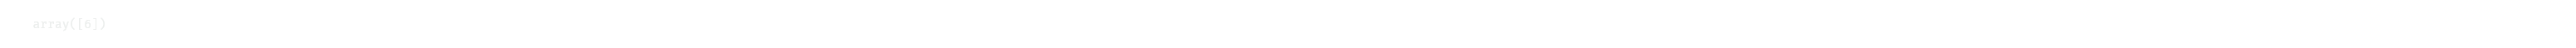

In [ ]:
def _empirical_modes() -> NDArray[np.int_]:
    I = (
        Iter.from_fn(lambda: Some(scoremin(20)))
        .take(1000)
        # collect the Iterator results in a collections.abc.Sequence object
        .collect(Seq)
        # pass it to np.array
        .pipe(np.array)
    )
    counts = np.bincount(I)
    return np.flatnonzero(counts == counts.max())

_empirical_modes()